# Fashion-MNIST (Kaggle): clustering

A stratified 3,000 of the 70,000 Fashion-MNIST images (Kaggle), pixels scaled to [0, 1] and reduced to 50 principal components. The ten clothing classes are the reference labels (report dataset D5).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/fashion_mnist_results.csv` and `fashion_mnist_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "fashion_mnist"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

Kaggle Fashion-MNIST: stratified 3,000 of 70,000 images, pixels / 255, PCA to 50.
3,000 points, 50 features, classes: 10


,pca_0,pca_1,pca_2,pca_3,pca_4,pca_5,pca_6,pca_7,pca_8,pca_9,...,pca_40,pca_41,pca_42,pca_43,pca_44,pca_45,pca_46,pca_47,pca_48,pca_49
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,...,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,...,-0.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00
std,4.43,3.50,2.04,1.84,1.63,1.53,1.29,1.14,0.99,0.96,...,0.38,0.37,0.37,0.36,0.35,0.35,0.34,0.34,0.33,0.33
min,-7.72,-6.52,-6.30,-5.57,-5.87,-6.11,-3.38,-4.54,-4.27,-3.16,...,-1.55,-1.57,-1.43,-1.69,-1.57,-1.15,-1.45,-2.02,-1.30,-1.79
25%,-3.79,-2.89,-1.36,-1.29,-1.00,-0.70,-0.89,-0.62,-0.55,-0.66,...,-0.24,-0.24,-0.22,-0.22,-0.22,-0.23,-0.21,-0.21,-0.22,-0.19
50%,-0.02,0.29,0.06,-0.02,-0.04,0.07,-0.06,-0.07,-0.02,-0.01,...,0.01,-0.00,-0.00,0.01,0.00,0.00,0.00,-0.00,-0.00,0.00
75%,3.55,2.67,1.51,1.20,0.84,1.08,0.85,0.52,0.52,0.65,...,0.26,0.23,0.23,0.23,0.23,0.22,0.21,0.21,0.22,0.20
max,10.20,8.23,6.94,6.88,6.85,4.12,5.18,5.11,4.62,3.30,...,1.63,1.85,1.41,1.83,1.74,1.34,1.35,1.82,1.14,1.18


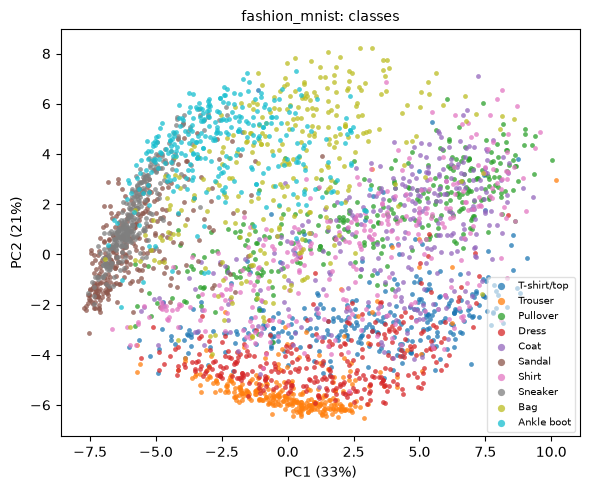

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/fashion_mnist_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save

x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 10, label-free choice: 7


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari,ari
0,2,134594.824,0.223,0.204,0.018,1.715,1426,1574,1.000,1.000,0.095
1,3,111052.250,0.226,0.166,0.060,1.544,870,1173,0.998,0.995,0.199
2,4,98253.658,0.215,0.138,0.077,1.588,527,854,0.997,0.988,0.251
3,5,90358.629,0.199,0.124,0.075,1.687,463,846,0.992,0.984,0.285
4,6,83426.792,0.193,0.107,0.086,1.598,430,565,0.977,0.943,0.322
5,7,78307.995,0.204,0.102,0.102,1.647,219,536,0.985,0.967,0.366
6,8,74499.980,0.194,0.098,0.096,1.609,191,490,0.941,0.723,0.369
7,9,71673.948,0.192,0.089,0.102,1.548,128,510,0.910,0.870,0.339
8,10,68314.213,0.202,0.082,0.120,1.470,106,479,0.832,0.660,0.343


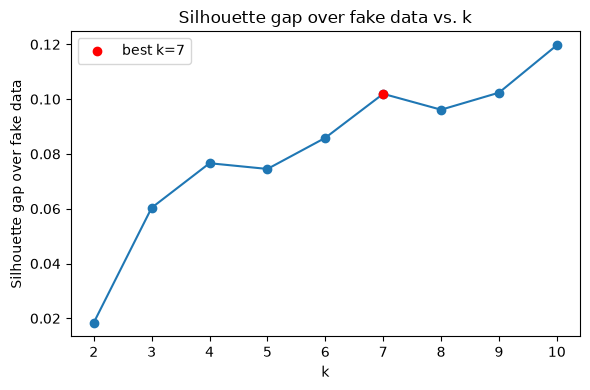

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/fashion_mnist_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save

fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),68315.417,25.0,0.050
K-Means,68314.213,45.0,0.066


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

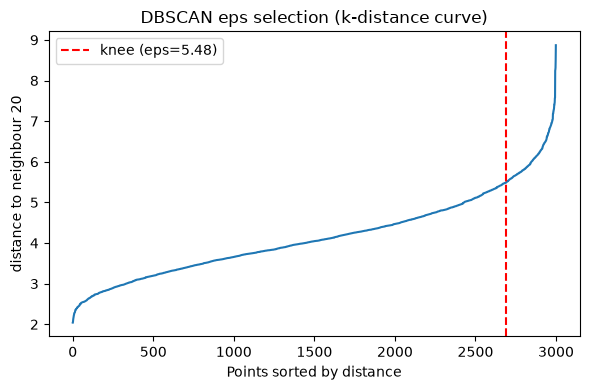

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/fashion_mnist_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save

min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=4.42, min_samples=40, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,2.485,10,0.50,8,0.826,0.068,0.293,0.033,False
1,3.728,10,0.75,2,0.255,0.741,-0.014,0.017,True
2,4.971,10,1.00,1,0.026,0.974,NaN,0.000,False
3,2.741,20,0.50,4,0.859,0.066,0.418,0.020,False
4,4.111,20,0.75,1,0.210,0.790,NaN,0.017,False
5,2.944,40,0.50,3,0.904,0.050,0.525,0.014,False
6,4.416,40,0.75,2,0.227,0.757,0.138,0.028,True
7,5.889,40,1.00,1,0.011,0.989,NaN,0.000,False
8,3.165,80,0.50,1,0.970,0.030,NaN,0.004,False
9,4.747,80,0.75,1,0.275,0.725,NaN,0.034,False


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=15, min_samples=5, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,ari,passes
0,5,NaN,28,0.709,0.076,0.228,0.050,False
1,5,5.0,28,0.709,0.076,0.228,0.050,False
2,5,10.0,7,0.605,0.364,0.046,0.052,False
3,10,NaN,5,0.606,0.364,0.104,0.052,False
4,10,5.0,17,0.713,0.076,0.301,0.050,False
5,10,10.0,5,0.606,0.364,0.104,0.052,False
6,15,NaN,3,0.660,0.329,0.180,0.050,False
7,15,5.0,2,0.329,0.663,0.039,0.023,True
8,15,10.0,5,0.606,0.364,0.104,0.052,False
9,20,NaN,4,0.857,0.052,0.432,0.021,False


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=10, covariance_type=full, label-free: n_components=6, covariance_type=full


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-270028.4,-209766.3,-412421.4,-282409.3
3,-261956.5,-161350.4,-385626.2,-279735.6
4,-256844.4,-133058.6,-368715.7,-276361.3
5,-253667.7,-124774.4,-356826.4,-274684.0
6,-251998.3,-117573.4,-344415.0,-271775.4
7,-248777.6,-118464.9,-338291.7,-268782.6
8,-247223.4,-120745.8,-331646.7,-266477.0
9,-246322.1,-124472.8,-326477.9,-265000.5
10,-244870.1,-121145.7,-320846.2,-261028.7


## 7. Clustering with Spectral

Spectral clustering at the K-Means k: an RBF affinity on Wine, a 10-nearest-neighbour graph elsewhere
(`run.SPECTRAL_AFFINITY_BY_DATASET`). A dense RBF affinity needs memory quadratic in the number of
points, so it is skipped on large data; the nearest-neighbour graph is sparse and runs at any size.

In [12]:
if run.is_too_large(ds, "Spectral"):
    print(f"skipping Spectral: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_DENSE_SPECTRAL:,}")
else:
    selections["Spectral"] = run.select_method(ds, "Spectral", selections)
    results["Spectral"] = run.fit_method(ds, "Spectral", selections["Spectral"])
    print(f"Spectral: {run.format_params(selections['Spectral'].params)}")

Spectral: n_clusters=10, affinity=nearest_neighbors


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores. The null columns refit each
method at its setting on a copy with every column shuffled: a silhouette near the null one means the
clusters are no stronger than on data without structure.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = [
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "davies_bouldin",
    "dbcv",
    "ari",
    "nmi",
    "fit_seconds",
    "null_silhouette",
]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,dbcv,ari,nmi,fit_seconds,null_silhouette
0,K-Means (random init),n_clusters=10,10,0.000,0.160,0.202,1.470,-0.549,0.344,0.512,0.050,0.081
1,K-Means,n_clusters=10,10,0.000,0.160,0.202,1.470,-0.549,0.343,0.512,0.066,0.083
2,DBSCAN,"eps=4.42, min_samples=40",2,0.227,0.757,0.138,1.211,-0.158,0.028,0.103,0.011,NaN
3,HDBSCAN,"min_cluster_size=15, min_samples=5",2,0.329,0.663,0.039,1.754,0.136,0.023,0.064,0.330,0.229
4,GMM,"n_components=10, covariance_type=full",10,0.000,0.183,0.129,2.497,-0.536,0.389,0.572,14.715,0.049
5,Spectral,"n_clusters=10, affinity=nearest_neighbors",10,0.000,0.200,0.194,1.568,-0.447,0.398,0.586,0.136,0.074


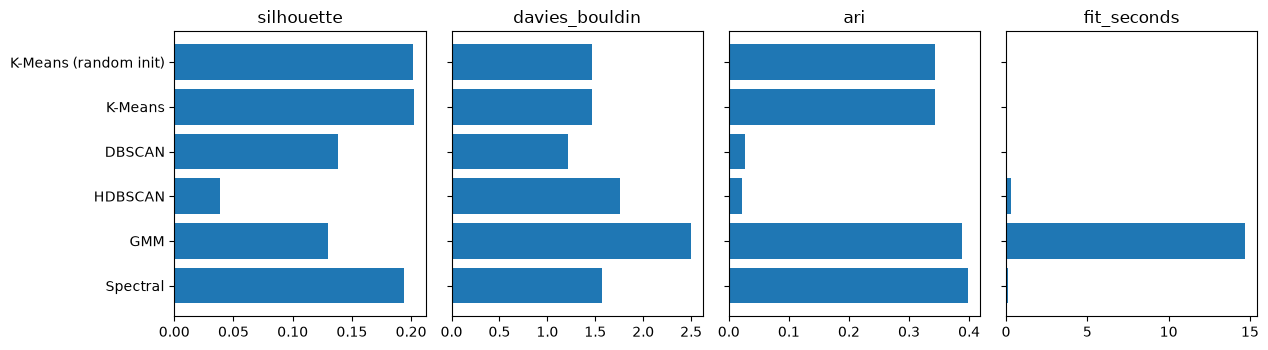

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/fashion_mnist_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save

metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

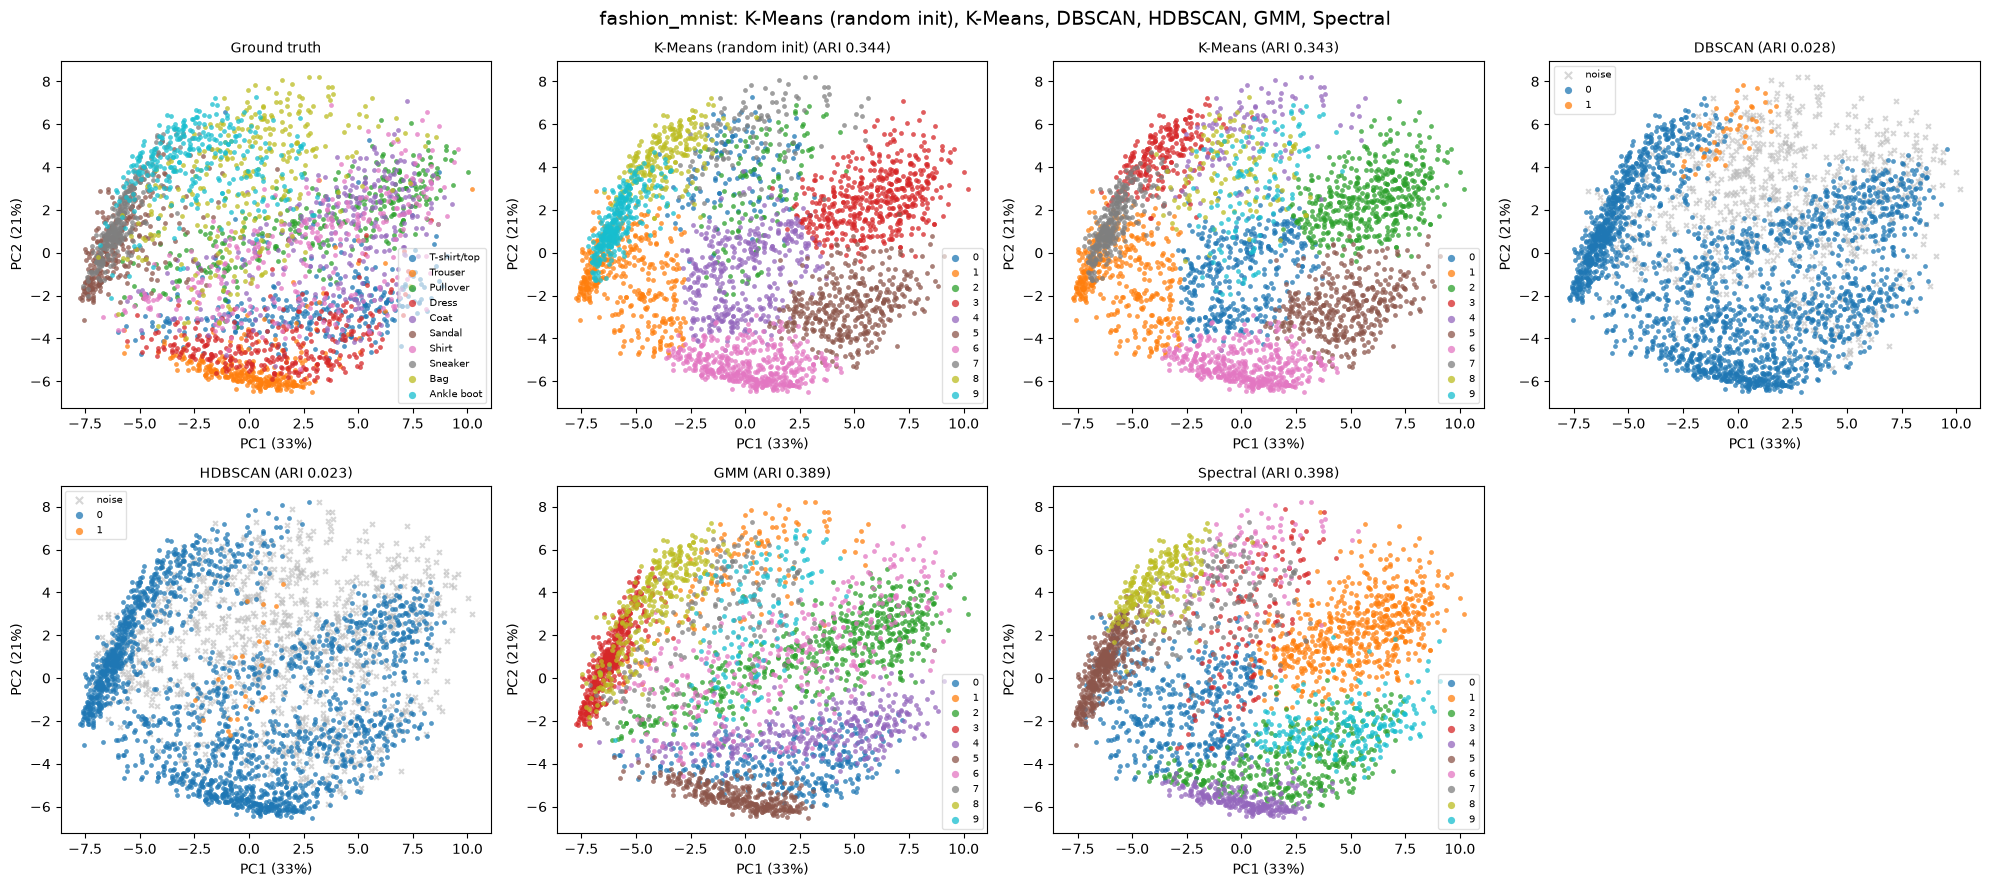

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/fashion_mnist_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save

fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")